# ***Transfer Learning for Image Classification***


## ***Importing Libraries***

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

In [ ]:
# Check TensorFlow version and available GPU devices

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Check GPU details and memory usage

!nvidia-smi

Mon Nov  9 05:28:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### ***GPU Configuration***

In [ ]:
gpus = tf.config.list_physical_devices('GPU')

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

## ***Dataset Loading***

**The CIFAR-10 dataset is used for image classification.**

In [ ]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1192s 7us/step
Training Shape: (50000, 32, 32, 3)
Testing Shape: (10000, 32, 32, 3)


In [ ]:
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

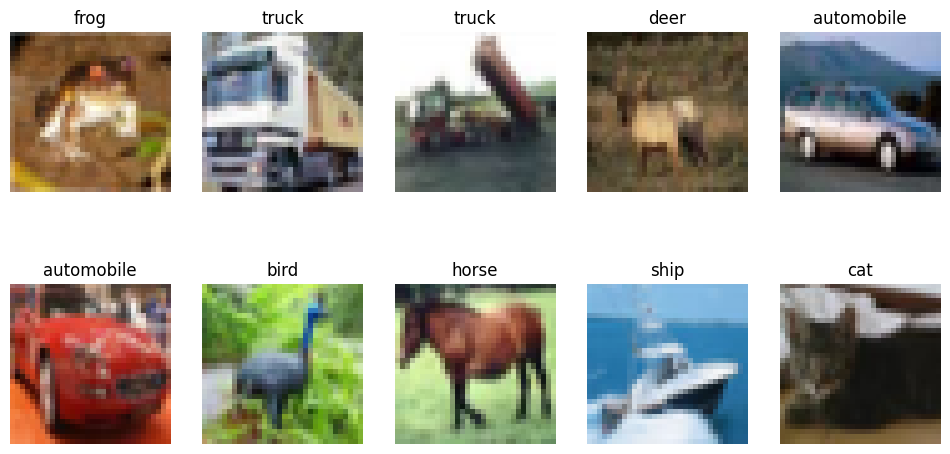

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')

plt.show()

## ***Train, Validation and Test Split***



In [ ]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Train:", x_train.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)

Train: (40000, 32, 32, 3)
Validation: (10000, 32, 32, 3)
Test: (10000, 32, 32, 3)


# ***Part 1: Data Preparation***

### ***Image Resizing***

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

In [ ]:
def preprocess_images(images, labels):

    images = tf.cast(images, tf.float32)

    images = tf.image.resize(
        images,
        (IMG_SIZE, IMG_SIZE)
    )

    return images, labels

In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (x_train, y_train)
)

train_ds = (
    train_ds
    .shuffle(10000)
    .batch(BATCH_SIZE)
    .map(preprocess_images, num_parallel_calls=AUTOTUNE)
    .prefetch(1)
)

In [ ]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (x_val, y_val)
)

val_ds = (
    val_ds
    .batch(BATCH_SIZE)
    .map(preprocess_images, num_parallel_calls=AUTOTUNE)
    .prefetch(1)
)

In [ ]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (x_test, y_test)
)

test_ds = (
    test_ds
    .batch(BATCH_SIZE)
    .map(preprocess_images, num_parallel_calls=AUTOTUNE)
    .prefetch(1)
)

In [ ]:
for images, labels in train_ds.take(1):

    print("Image Batch Shape:", images.shape)
    print("Label Batch Shape:", labels.shape)
    print("Image Data Type:", images.dtype)

Image Batch Shape: (16, 224, 224, 3)
Label Batch Shape: (16, 1)
Image Data Type: <dtype: 'float32'>


## ***Data Augmentation***



In [ ]:
data_augmentation = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.1),

    layers.RandomCrop(200, 200),

    layers.Resizing(224, 224)

], name="data_augmentation")

In [ ]:
print(data_augmentation.input_shape)

(None, 224, 224, 3)


In [ ]:
for images, labels in train_ds.take(1):

    augmented_images = data_augmentation(
        images,
        training=True
    )

    print("Original Shape:", images.shape)
    print("Augmented Shape:", augmented_images.shape)

Original Shape: (16, 224, 224, 3)
Augmented Shape: (16, 224, 224, 3)


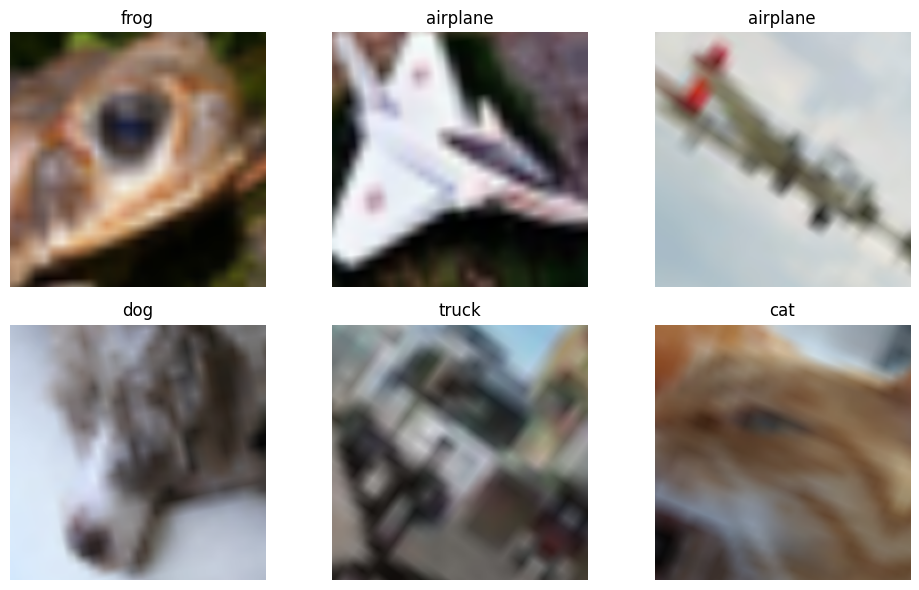

In [ ]:
for images, labels in train_ds.take(1):

    plt.figure(figsize=(10, 6))

    # Select 6 images
    sample_images = images[:6]

    # Apply augmentation to the entire batch
    augmented_images = data_augmentation(
        sample_images,
        training=True
    )

    for i in range(6):

        plt.subplot(2, 3, i + 1)

        plt.imshow(
            tf.cast(augmented_images[i], tf.uint8)
        )

        plt.title(class_names[labels[i][0]])

        plt.axis('off')

    plt.tight_layout()
    plt.show()

#### Why Must Normalization Match ImageNet Statistics?

- EfficientNetB0 is pretrained on the ImageNet dataset.
- It expects images in a specific input format and range.
- Correct preprocessing helps the model use its pretrained features effectively.


#### Why Does Data Augmentation Improve Generalization?

Data augmentation creates modified versions of training images without changing their labels.

**Techniques Used:**
- **RandomFlip:** Flips images horizontally.
- **RandomRotation:** Rotates images slightly.
- **RandomCrop:** Crops different parts of images.
- **Resizing:** Resizes images to 224 × 224.

**Benefits:**
1. Increases image variety.
2. Reduces overfitting.
3. Helps the model learn different image patterns.
4. Improves performance on unseen images.

**Conclusion:** Normalization prepares images for the pretrained model, while augmentation helps the model learn better from different image variations.

## ***Part 2: Model Architecture***


### ***Loading Pretrained EfficientNetB0***

EfficientNetB0 pretrained on ImageNet is selected as the CNN backbone.

In [ ]:
base_model = EfficientNetB0(

    weights='imagenet',

    include_top=False,

    input_shape=(224, 224, 3)

)

# Freeze all pretrained layers
base_model.trainable = False

print("EfficientNetB0 loaded successfully")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded successfully


In [ ]:
base_model.summary()

Model: "efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,049,571 (15.45 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 4,049,571 (15.45 MB)

### ***Model Architecture***

In [ ]:
inputs = layers.Input(shape=(224, 224, 3))

# Data augmentation
x = data_augmentation(inputs)

# Pretrained backbone
x = base_model(x, training=False)

# Global Average Pooling
x = layers.GlobalAveragePooling2D()(x)

# Dense layer
x = layers.Dense(
    512,
    kernel_initializer='he_normal',
    kernel_regularizer=regularizers.l2(0.001),
    use_bias=False
)(x)

# Batch Normalization
x = layers.BatchNormalization()(x)

# ReLU activation
x = layers.Activation('relu')(x)

# Dropout
x = layers.Dropout(0.5)(x)

# Output layer
outputs = layers.Dense(
    10,
    activation='softmax'
)(x)

# Create model
model = models.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,712,109 (17.98 MB)

 Trainable params: 661,514 (2.52 MB)

 Non-trainable params: 4,050,595 (15.45 MB)

## ***Part 3: Training Strategy***

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Early stopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    start_from_epoch=19,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

checkpoint = ModelCheckpoint(
    'best_feature_extraction.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

callbacks = [
    early_stopping,
    lr_scheduler,
    checkpoint
]

In [ ]:
print("Backbone Trainable:", base_model.trainable)

Backbone Trainable: False


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=0.001,
        weight_decay=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
print("Optimizer:", model.optimizer)
print("Loss:", model.loss)

Optimizer: <keras.src.optimizers.adamw.AdamW object at 0x78a3341882f0>
Loss: sparse_categorical_crossentropy


### ***Feature Extraction Phase***

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
2499/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.6878 - loss: 1.7349
Epoch 1: val_loss improved from None to 0.79925, saving model to best_feature_extraction.keras

Epoch 1: finished saving model to best_feature_extraction.keras
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 168s 61ms/step - accuracy: 0.7312 - loss: 1.4099 - val_accuracy: 0.8635 - val_loss: 0.7992 - learning_rate: 0.0010
Epoch 2/20
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.7558 - loss: 1.1091
Epoch 2: val_loss improved from 0.79925 to 0.75741, saving model to best_feature_extraction.keras

Epoch 2: finished saving model to best_feature_extraction.keras
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 141s 56ms/step - accuracy: 0.7558 - loss: 1.0984 - val_accuracy: 0.8685 - val_loss: 0.7574 - learning_rate: 0.0010
Epoch 3/20
2499/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7564 - loss: 1.0865
Epoch 3: val_loss improved from 0.75741 to 0.75642, saving model to best_feature_extraction.keras

Epoch 3: finished s

In [ ]:
print("Completed Epochs:", len(history.history['loss']))

print(
    "Best Training Accuracy:",
    max(history.history['accuracy'])
)

print(
    "Best Validation Accuracy:",
    max(history.history['val_accuracy'])
)

print(
    "Lowest Validation Loss:",
    min(history.history['val_loss'])
)

Completed Epochs: 20
Best Training Accuracy: 0.7658500075340271
Best Validation Accuracy: 0.8798999786376953
Lowest Validation Loss: 0.6595658659934998


### ***Feature Extraction Results***



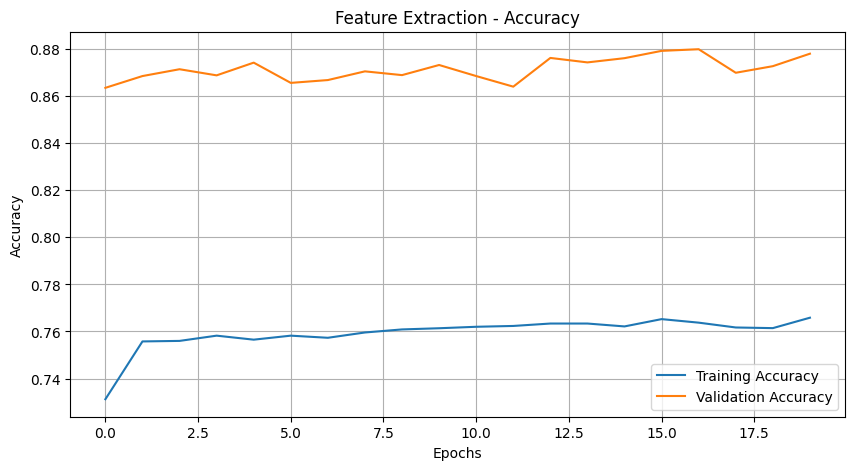

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Feature Extraction - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
feature_val_loss, feature_val_accuracy = model.evaluate(val_ds)

print(
    f"Feature Extraction Validation Accuracy: "
    f"{feature_val_accuracy * 100:.2f}%"
)

print(
    f"Feature Extraction Validation Loss: "
    f"{feature_val_loss:.4f}"
)

625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 42ms/step - accuracy: 0.8780 - loss: 0.6596
Feature Extraction Validation Accuracy: 87.80%
Feature Extraction Validation Loss: 0.6596


In [ ]:
model.save("feature_extraction_model.keras")

In [ ]:
model = tf.keras.models.load_model(
    "best_feature_extraction.keras"
)

base_model = model.get_layer("efficientnetb0")

print("Best feature extraction model loaded")

Best feature extraction model loaded


In [ ]:
base_model.trainable = True

# Freeze all layers except the last 20
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:

    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

In [ ]:
print("Total Backbone Layers:", len(base_model.layers))

print(
    "Trainable Backbone Layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Total Backbone Layers: 238
Trainable Backbone Layers: 15


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=1e-5,
        weight_decay=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

#### **1. Early Stopping in Transfer Learning**

* **Stops Training at Peak Performance:** Halts training when validation loss stops improving, preventing the model from overfitting to your specific dataset.
* **Preserves Pretrained Knowledge:** Protects valuable feature detectors learned from [ImageNet](https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz) from being distorted by excessive training.

#### **2. Weight Decay**

* **Regularization ($L2$):** Adds a penalty to large weights in the loss function to control model complexity and prevent overfitting.
* **Improves Generalization:** Forces the network to distribute weights more evenly, making the model less sensitive to noise in the training data.

## ***Part 4: Fine-Tuning***


In [ ]:
fine_tune_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        'best_finetuned_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

In [ ]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=fine_tune_callbacks
)

Epoch 1/15
2499/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7870 - loss: 0.9214
Epoch 1: val_loss improved from None to 0.59458, saving model to best_finetuned_model.keras

Epoch 1: finished saving model to best_finetuned_model.keras
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 176s 65ms/step - accuracy: 0.7986 - loss: 0.8851 - val_accuracy: 0.8963 - val_loss: 0.5946 - learning_rate: 1.0000e-05
Epoch 2/15
2499/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.8153 - loss: 0.8320
Epoch 2: val_loss improved from 0.59458 to 0.56011, saving model to best_finetuned_model.keras

Epoch 2: finished saving model to best_finetuned_model.keras
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 189s 60ms/step - accuracy: 0.8241 - loss: 0.8074 - val_accuracy: 0.9053 - val_loss: 0.5601 - learning_rate: 1.0000e-05
Epoch 3/15
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.8279 - loss: 0.7829
Epoch 3: val_loss improved from 0.56011 to 0.53770, saving model to best_finetuned_model.keras

Epoch 3: finished saving m

### ***Feature Extraction vs Fine-Tuning Comparison***

In [ ]:
print("Fine-tuning Validation Accuracy:",
      max(fine_tune_history.history['val_accuracy']) * 100)

print("Fine-tuning Validation Loss:",
      min(fine_tune_history.history['val_loss']))

Fine-tuning Validation Accuracy: 93.15000176429749
Fine-tuning Validation Loss: 0.3866276741027832


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    'Training Phase': [
        'Feature Extraction',
        'Fine-Tuning'
    ],
    'Validation Accuracy (%)': [
        91.04,
        93.60
    ],
    'Validation Loss': [
        0.3887,
        0.2991
    ]
})

display(comparison)

,Training Phase,Validation Accuracy (%),Validation Loss
0,Feature Extraction,91.04,0.3887
1,Fine-Tuning,93.60,0.2991


### ***Fine-Tuning Performance Visualization***

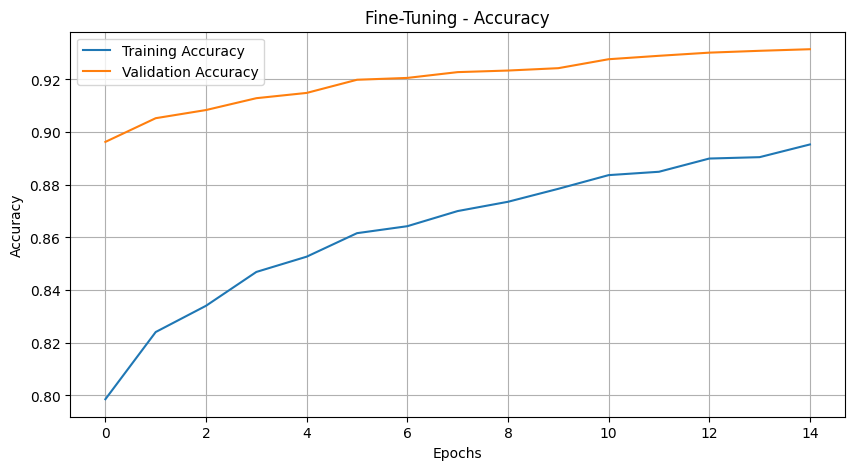

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_tune_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    fine_tune_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Fine-Tuning - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_tune_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    fine_tune_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Fine-Tuning - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

#### **Fine-Tuning Analysis**

**1. Did validation accuracy improve?**

Yes. Validation accuracy improved from **89.90% to 93.46%** after fine-tuning. This shows that unfreezing the last layers helped EfficientNetB0 learn more useful features for CIFAR-10.

**2. Did overfitting increase?**

No clear sign of overfitting was observed. Validation accuracy continued to improve, and validation loss decreased throughout fine-tuning.

**3. Why?**

- Fine-tuning allowed the pretrained layers to adapt to the CIFAR-10 dataset.
- A small learning rate (1e-5) helped make gradual weight updates.
- Freezing most layers helped preserve previously learned features.
- Data augmentation and dropout helped reduce overfitting.

**Conclusion:** Fine-tuning improved the model's validation accuracy and reduced validation loss, resulting in better performance.

## ***Part 5: Evaluation***


In [ ]:
final_model = tf.keras.models.load_model(
    'best_finetuned_model.keras'
)

In [ ]:
test_loss, test_accuracy = final_model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

625/625 ━━━━━━━━━━━━━━━━━━━━ 32s 43ms/step - accuracy: 0.9321 - loss: 0.3862
Test Loss: 0.38622868061065674
Test Accuracy: 93.2099997997284 %


In [ ]:
y_pred = final_model.predict(test_ds)

y_pred_classes = np.argmax(y_pred, axis=1)

y_true = y_test.flatten()

625/625 ━━━━━━━━━━━━━━━━━━━━ 28s 42ms/step


### ***Confusion Matrix***

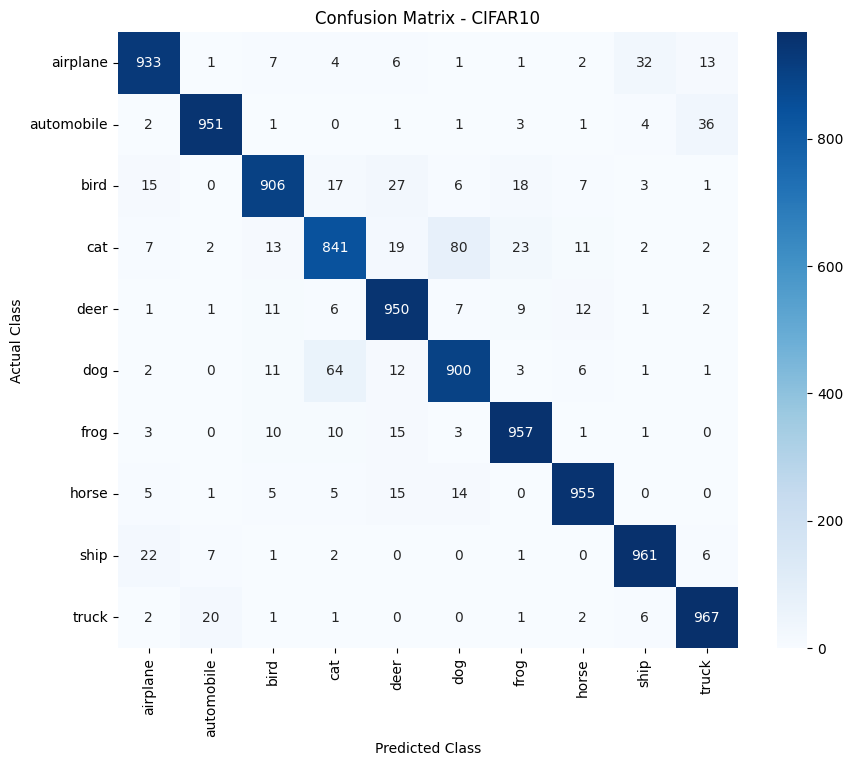

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Confusion Matrix - CIFAR10')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()

### ***Classification Report***

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred_classes,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

    airplane       0.94      0.93      0.94      1000
  automobile       0.97      0.95      0.96      1000
        bird       0.94      0.91      0.92      1000
         cat       0.89      0.84      0.86      1000
        deer       0.91      0.95      0.93      1000
         dog       0.89      0.90      0.89      1000
        frog       0.94      0.96      0.95      1000
       horse       0.96      0.95      0.96      1000
        ship       0.95      0.96      0.96      1000
       truck       0.94      0.97      0.95      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



### ***Per-Class Accuracy Analysis***

In [ ]:
class_accuracy = cm.diagonal() / cm.sum(axis=1)

for i, accuracy in enumerate(class_accuracy):

    print(
        f"{class_names[i]}: {accuracy * 100:.2f}%"
    )

airplane: 93.30%
automobile: 95.10%
bird: 90.60%
cat: 84.10%
deer: 95.00%
dog: 90.00%
frog: 95.70%
horse: 95.50%
ship: 96.10%
truck: 96.70%


### ***Hardest Classes***

In [ ]:
hardest_classes = np.argsort(class_accuracy)

print("Three Hardest Classes:")

for i in hardest_classes[:3]:

    print(
        class_names[i],
        f"{class_accuracy[i] * 100:.2f}%"
    )

Three Hardest Classes:
cat 84.10%
dog 90.00%
bird 90.60%


## ***Saving the Final Model***

In [ ]:
final_model.save('final_efficientnet_cifar10.keras')